In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
df = pd.read_csv("lab_ticket_resolution.csv")
print(df.shape)
print(df.dtypes)
print(df.describe(include="all"))
print(df.isna().sum())

(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000               5.800000   
75%          NaN   

In [2]:
df = pd.read_csv("lab_ticket_resolution.csv")

print("Dataset shape:")
print(df.shape)

print("\nData types:")
print(df.dtypes)

print("\nDescriptive statistics:")
print(df.describe(include="all"))

print("\nMissing values:")
print(df.isna().sum())

print("\nFirst five rows:")
print(df.head())


Dataset shape:
(240, 6)

Data types:
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object

Descriptive statistics:
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54

In [3]:
target = "resolution_hours"

features = [
"complexity_score",
"team_experience_years"
]

X = df[features]
y = df[target]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())


Features:
   complexity_score  team_experience_years
0                 6                    5.6
1                 9                   11.5
2                 6                    3.3
3                 5                    9.6
4                 3                    6.4

Target:
0    24.77
1    33.43
2    17.82
3    19.54
4    11.04
Name: resolution_hours, dtype: float64


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [5]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (192, 2)
Testing features: (48, 2)
Training targets: (192,)
Testing targets: (48,)


In [10]:
baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("Baseline Results")
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)
print("R²:", baseline_r2)


Baseline Results
MAE: 9.113951822916667
RMSE: 10.597684800766308
R²: -0.021016765260001957


In [11]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_predictions)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression Results")
print("MAE:", linear_mae)
print("RMSE:", linear_rmse)
print("R²:", linear_r2)

Linear Regression Results
MAE: 2.9060129859502593
RMSE: 3.572274354879709
R²: 0.8839886480141969


In [12]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression

cv = KFold(n_splits=5, shuffle=True, random_state=42)

for degree in [2, 3]:

    poly_model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    scores = cross_val_score(
        poly_model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error"
    )

    print(f"Degree {degree}")
    print("Cross-validation MAE:", -scores.mean())
    print()

Degree 2
Cross-validation MAE: 3.131261273764686

Degree 3
Cross-validation MAE: 3.1620030669380585



In [13]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

alphas = [0.01, 0.1, 1, 10, 100]

ridge_search = GridSearchCV(
    make_pipeline(
        StandardScaler(),
        Ridge()
    ),
    param_grid={"ridge__alpha": alphas},
    cv=cv,
    scoring="neg_mean_absolute_error"
)

lasso_search = GridSearchCV(
    make_pipeline(
        StandardScaler(),
        Lasso(max_iter=10000)
    ),
    param_grid={"lasso__alpha": alphas},
    cv=cv,
    scoring="neg_mean_absolute_error"
)

ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_search.best_params_)
print("Best Ridge CV MAE:", -ridge_search.best_score_)

print("Best Lasso alpha:", lasso_search.best_params_)
print("Best Lasso CV MAE:", -lasso_search.best_score_)

Best Ridge alpha: {'ridge__alpha': 0.01}
Best Ridge CV MAE: 3.168179510394689
Best Lasso alpha: {'lasso__alpha': 0.01}
Best Lasso CV MAE: 3.1688399463972354


In [14]:
best_degree = 2

best_poly_model = make_pipeline(
    PolynomialFeatures(
        degree=best_degree,
        include_bias=False
    ),
    StandardScaler(),
    LinearRegression()
)

best_poly_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('polynomialfeatures', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['complexity_score','team_experience_years']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


In [15]:
models = {
    "Dummy": dummy_model,
    "Linear Regression": linear_model,
    "Polynomial Regression": best_poly_model,
    "Ridge": ridge_search.best_estimator_,
    "Lasso": lasso_search.best_estimator_
}

results = []

predictions = {}

for name, model in models.items():

    if name == "Dummy":
        y_pred = dummy_predictions
    elif name == "Linear Regression":
        y_pred = linear_predictions
    else:
        y_pred = model.predict(X_test)

    predictions[name] = y_pred

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,MAE,RMSE,R2
0,Dummy,9.114,10.598,-0.021
1,Linear Regression,2.906,3.572,0.884
2,Polynomial Regression,3.020,3.741,0.873
3,Ridge,2.906,3.572,0.884
4,Lasso,2.907,3.572,0.884


In [16]:
print(
    "Lowest MAE:",
    results_df.loc[results_df["MAE"].idxmin(), "Model"]
)

Lowest MAE: Ridge


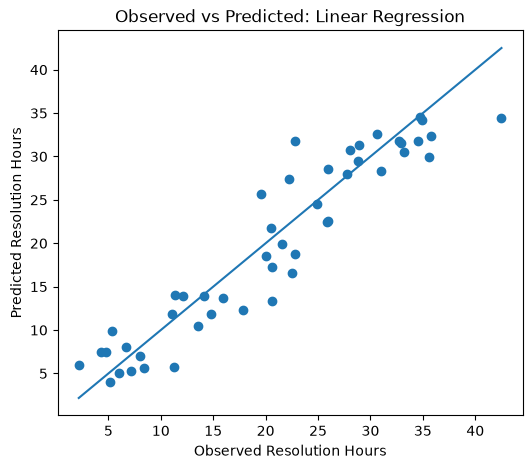

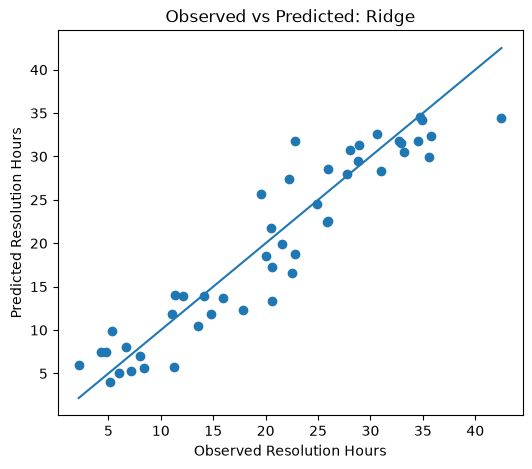

In [17]:
import matplotlib.pyplot as plt

for name in ["Linear Regression", "Ridge"]:

    y_pred = predictions[name]

    plt.figure(figsize=(6, 5))
    plt.scatter(y_test, y_pred)

    low = min(y_test.min(), y_pred.min())
    high = max(y_test.max(), y_pred.max())

    plt.plot([low, high], [low, high])

    plt.xlabel("Observed Resolution Hours")
    plt.ylabel("Predicted Resolution Hours")
    plt.title(f"Observed vs Predicted: {name}")

    plt.show()

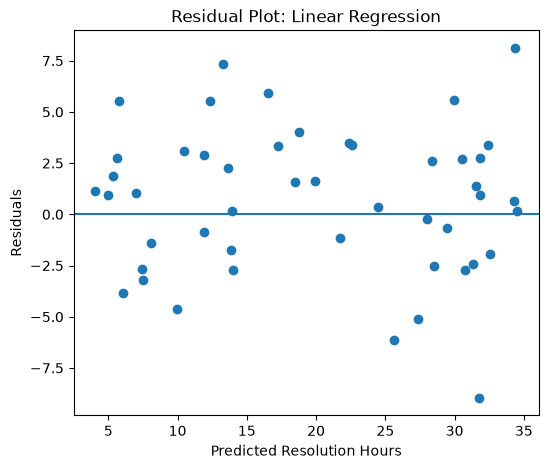

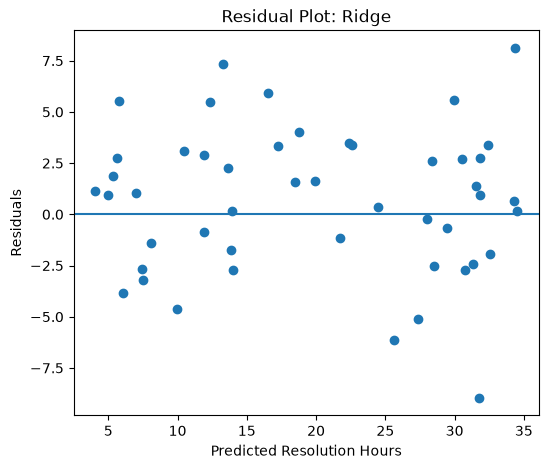

In [18]:
for name in ["Linear Regression", "Ridge"]:

    y_pred = predictions[name]
    residuals = y_test.to_numpy() - y_pred

    plt.figure(figsize=(6, 5))
    plt.scatter(y_pred, residuals)

    plt.axhline(y=0)

    plt.xlabel("Predicted Resolution Hours")
    plt.ylabel("Residuals")
    plt.title(f"Residual Plot: {name}")

    plt.show()

# Write a short recommendation: which model would you choose for this dataset, what evidence supports it, and what further data or checks would be needed?
I recommend  Linear Regression because it achieved the lowest MAE and RMSE, provided a strong R² score, and is simpler to interpret than Polynomial Regression. Although further testing on real-world data is necessary before using the model in practice.  

# Why is the mean baseline useful even though it ignores all features?
The Dummy Regression model provides a baseline for comparing the performance of other models. It predicts the mean resolution time for every ticket. Its MAE is 9.114, RMSE is 10.598, and R² is -0.021. The other models perform much better, showing that using input features helps predict ticket resolution time more accurately than simply predicting the average.

# Which model has the lowest MAE? Which has the lowest RMSE? Are they the same, and why might they differ?
Linear Regression and Ridge Regression achieved the lowest MAE of 2.906 and RMSE of 3.572. Because the metrics measure errors differently.

# Did polynomial features improve validation performance? What is the evidence of possible overfitting?
They did not improve the results. However, the test results alone are not enough to confirm overfitting; comparing training and cross-validation performance would provide stronger evidence.

# How did regularization affect performance and coefficient magnitudes?
Ridge and Lasso penalize large coefficients. Regularization may improve generalization by controlling model complexity, although it can also lead to underfitting if the penalty is too strong.

# Why is scaling included in the Ridge/Lasso pipeline? 
Feature scaling is important because Ridge and Lasso penalize the sizes of model coefficients. If features have very different scales, the regularization penalty may affect them unevenly. StandardScaler transforms features to comparable scales, helping regularization work more fairly and making model training more reliable.

# Identify one potential leakage issue in the dataset and explain how you handled it.
Lines_changed, I excluded it because we assumed the prediction must be made at ticket submission time.

# Would a random split be appropriate if tickets were collected over several years or came from repeated customers/teams?
No. A random train-test split is suitable when the data points are reasonably independent and the training and testing data represent similar conditions. However, if the goal is to predict future ticket resolution times, a chronological split may be more appropriate because it trains the model on earlier tickets and tests it on later tickets. If tickets are grouped by team or customer, a group-based split may also be necessary to evaluate performance on unseen groups.

# What additional tests would you perform before deploying this model?
Before deployment, the model should be tested on representative real-world data. The developer should check for missing values, incorrect data, data leakage, and unusual prediction errors. Residual plots should be examined to identify patterns in the errors. The model should also be evaluated on different types of tickets and monitored over time to ensure that its predictions remain reliable.